In [2]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../torgo_metadata.csv")

print(df.shape)
df.head()

(17635, 9)


,file,group,gender,condition,filename,microphone,speaker,session,recording_number
0,../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...,F_Con,Female,Control,wav_arrayMic_FC01S01_0001.wav,arrayMic,FC01,S01,0001
1,../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...,F_Con,Female,Control,wav_arrayMic_FC01S01_0002.wav,arrayMic,FC01,S01,0002
2,../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...,F_Con,Female,Control,wav_arrayMic_FC01S01_0003.wav,arrayMic,FC01,S01,0003
3,../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...,F_Con,Female,Control,wav_arrayMic_FC01S01_0004.wav,arrayMic,FC01,S01,0004
4,../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...,F_Con,Female,Control,wav_arrayMic_FC01S01_0005.wav,arrayMic,FC01,S01,0005


In [4]:
control_file = df[df["condition"] == "Control"].iloc[0]["file"]

print(control_file)

control_audio, control_sr = librosa.load(
    control_file,
    sr=None
)

print("Sampling rate:", control_sr)
print("Duration:", len(control_audio) / control_sr)

../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayMic_FC01S01_0001.wav
Sampling rate: 16000
Duration: 9.3


In [5]:
f0, voiced_flag, voiced_prob = librosa.pyin(
    control_audio,
    fmin=65,
    fmax=500,
    sr=control_sr
)

print("F0 values:", len(f0))
print("Valid F0 values:", np.sum(~np.isnan(f0)))

F0 values: 291
Valid F0 values: 105


In [6]:
valid_f0 = f0[~np.isnan(f0)]

print("Mean F0:", np.mean(valid_f0))
print("Median F0:", np.median(valid_f0))
print("Minimum F0:", np.min(valid_f0))
print("Maximum F0:", np.max(valid_f0))
print("F0 standard deviation:", np.std(valid_f0))

Mean F0: 180.12610297180262
Median F0: 176.56241769755178
Minimum F0: 86.26486325200693
Maximum F0: 476.842102466429
F0 standard deviation: 87.16110163794852


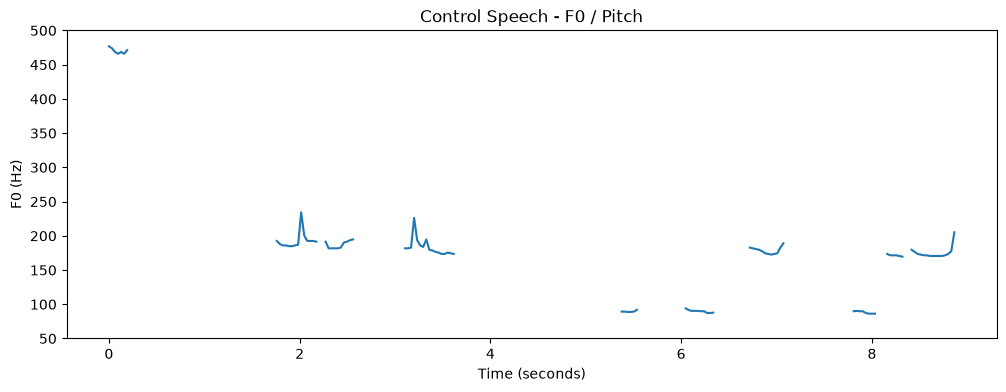

In [7]:
times = librosa.times_like(f0, sr=control_sr)

plt.figure(figsize=(12, 4))

plt.plot(times, f0)

plt.title("Control Speech - F0 / Pitch")
plt.xlabel("Time (seconds)")
plt.ylabel("F0 (Hz)")

plt.ylim(50, 500)

plt.show()

In [8]:
dys_file = df[df["condition"] == "Dysarthria"].iloc[0]["file"]

print(dys_file)

dys_audio, dys_sr = librosa.load(
    dys_file,
    sr=None
)

dys_f0, dys_voiced_flag, dys_voiced_prob = librosa.pyin(
    dys_audio,
    fmin=65,
    fmax=500,
    sr=dys_sr
)

valid_dys_f0 = dys_f0[~np.isnan(dys_f0)]

print("Mean F0:", np.mean(valid_dys_f0))
print("Median F0:", np.median(valid_dys_f0))
print("Minimum F0:", np.min(valid_dys_f0))
print("Maximum F0:", np.max(valid_dys_f0))
print("F0 standard deviation:", np.std(valid_dys_f0))

../torgo\F_Dys\wav_arrayMic_F01\wav_arrayMic_F01_0001.wav
Mean F0: 245.50128677357003
Median F0: 241.19137040474044
Minimum F0: 206.36213675586595
Maximum F0: 361.3787371590077
F0 standard deviation: 26.535678964605925


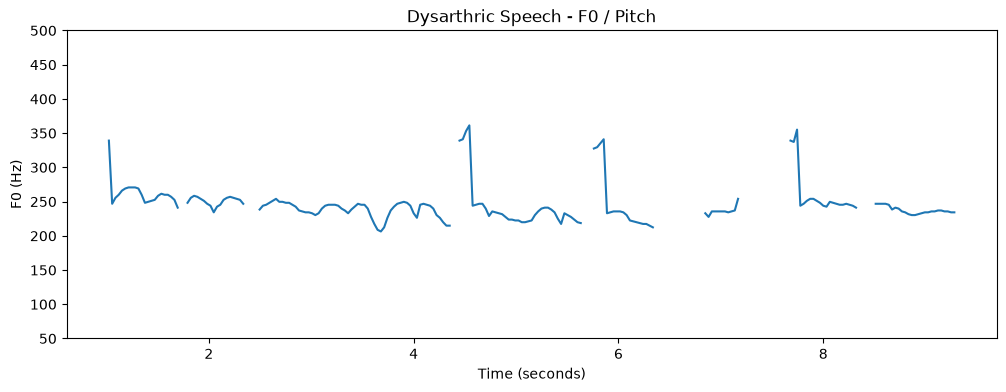

In [9]:
dys_times = librosa.times_like(dys_f0, sr=dys_sr)

plt.figure(figsize=(12, 4))

plt.plot(dys_times, dys_f0)

plt.title("Dysarthric Speech - F0 / Pitch")
plt.xlabel("Time (seconds)")
plt.ylabel("F0 (Hz)")

plt.ylim(50, 500)

plt.show()

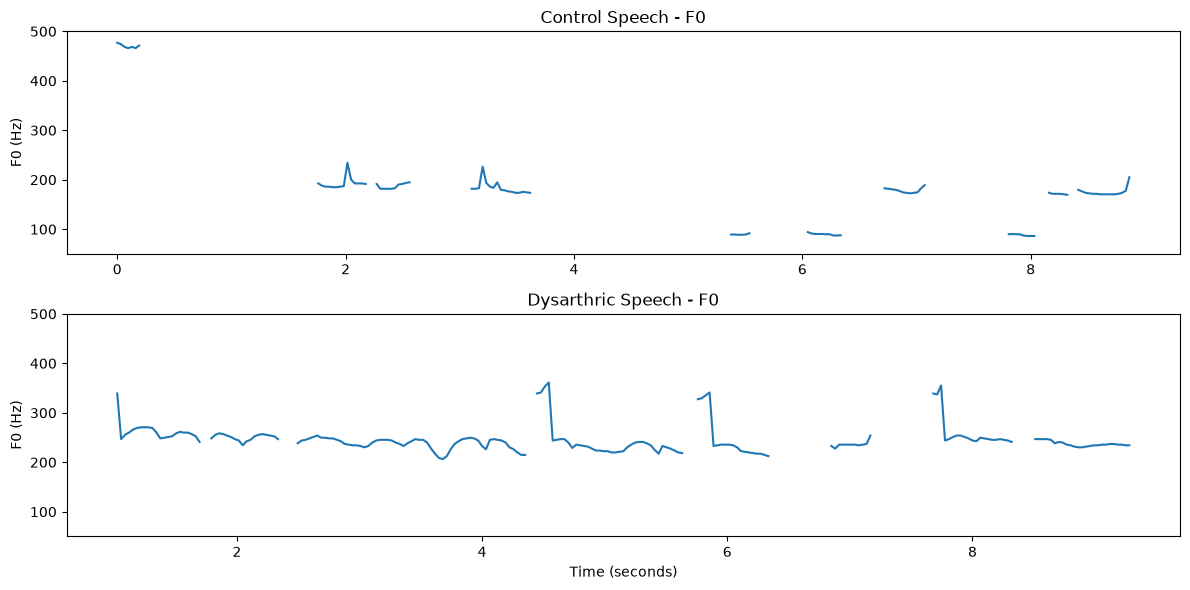

In [10]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(times, f0)
plt.title("Control Speech - F0")
plt.ylabel("F0 (Hz)")
plt.ylim(50, 500)

plt.subplot(2, 1, 2)
plt.plot(dys_times, dys_f0)
plt.title("Dysarthric Speech - F0")
plt.ylabel("F0 (Hz)")
plt.xlabel("Time (seconds)")
plt.ylim(50, 500)

plt.tight_layout()
plt.show()

In [11]:
def extract_pitch_features(file_path):

    try:
        # Load audio
        audio, sr = librosa.load(file_path, sr=None)

        # Check for empty audio
        if len(audio) == 0:
            print("EMPTY AUDIO:", file_path)
            return None

        # Estimate fundamental frequency (F0)
        f0 = librosa.yin(
            audio,
            fmin=65,
            fmax=500,
            sr=sr
        )

        # Remove invalid values
        f0_valid = f0[np.isfinite(f0)]

        if len(f0_valid) == 0:
            return None

        # Basic F0 statistics
        mean_f0 = np.mean(f0_valid)
        median_f0 = np.median(f0_valid)
        min_f0 = np.min(f0_valid)
        max_f0 = np.max(f0_valid)
        std_f0 = np.std(f0_valid)

        return {
            "mean_f0": mean_f0,
            "median_f0": median_f0,
            "min_f0": min_f0,
            "max_f0": max_f0,
            "std_f0": std_f0
        }

    except Exception as e:

        print("ERROR:", file_path, e)

        return None

In [12]:
pitch_results = []

for index, row in df.iterrows():

    features = extract_pitch_features(row["file"])

    if features is None:
        continue

    features["condition"] = row["condition"]
    features["gender"] = row["gender"]
    features["speaker"] = row["speaker"]
    features["microphone"] = row["microphone"]

    pitch_results.append(features)

    if index % 500 == 0:
        print("Processed:", index)

Processed: 0
EMPTY AUDIO: ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayMic_FC01S01_0256.wav
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
Processed: 5500
Processed: 6000
ERROR: ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0067.wav Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0067.wav': Format not recognised.
ERROR: ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0068.wav Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0068.wav': Format not recognised.
Processed: 6500
Processed: 7000
Processed: 7500
Processed: 8000
Processed: 8500
Processed: 9000
Processed: 9500
Processed: 10000
Processed: 10500
Processed: 11000
Processed: 11500
Processed: 12000
Processed: 12500
Processed: 13000
Processed: 13500
Processed: 14000
Processed: 14500
Processed: 15000
Processed: 15500
Processed: 16000
Processed: 16500
Processed: 17000
Processed: 17500


In [13]:
pitch_df = pd.DataFrame(pitch_results)

print("Shape:", pitch_df.shape)
print(pitch_df.head())

Shape: (17632, 9)
      mean_f0   median_f0     min_f0      max_f0     std_f0 condition  gender  \
0  160.518512  172.031150  65.026943  500.000000  91.476049   Control  Female   
1  164.382461  170.279890  65.025203  500.000000  76.519516   Control  Female   
2  119.178361   96.406916  65.024031  457.345456  85.951384   Control  Female   
3  166.572142  177.359683  64.777328  500.000000  54.919526   Control  Female   
4  111.243299   88.403053  65.025919  466.288165  66.820464   Control  Female   

  speaker microphone  
0    FC01   arrayMic  
1    FC01   arrayMic  
2    FC01   arrayMic  
3    FC01   arrayMic  
4    FC01   arrayMic  


In [14]:
print("Total successfully processed:", len(pitch_df))

print("\nCondition:")
print(pitch_df["condition"].value_counts())

print("\nMissing F0:")
print(pitch_df["median_f0"].isna().sum())

Total successfully processed: 17632

Condition:
condition
Control       11455
Dysarthria     6177
Name: count, dtype: int64

Missing F0:
0


In [15]:
pitch_summary = pitch_df.groupby("condition")[
    ["mean_f0", "median_f0", "min_f0", "max_f0", "std_f0"]
].mean()

print(pitch_summary)

              mean_f0   median_f0     min_f0      max_f0     std_f0
condition                                                          
Control     122.29248  100.296023  66.685873  355.217878  67.887143
Dysarthria  147.85162  121.331988  68.660542  417.047346  84.612082


In [16]:
gender_pitch = pitch_df.groupby(
    ["gender", "condition"]
)[
    ["mean_f0", "median_f0", "std_f0"]
].mean()

print(gender_pitch)

                      mean_f0   median_f0     std_f0
gender condition                                    
Female Control     129.178835  105.524093  74.788221
       Dysarthria  151.273729  125.510574  84.345161
Male   Control     117.540713   96.688516  63.125217
       Dysarthria  145.693378  118.696655  84.780422


<Figure size 800x500 with 0 Axes>

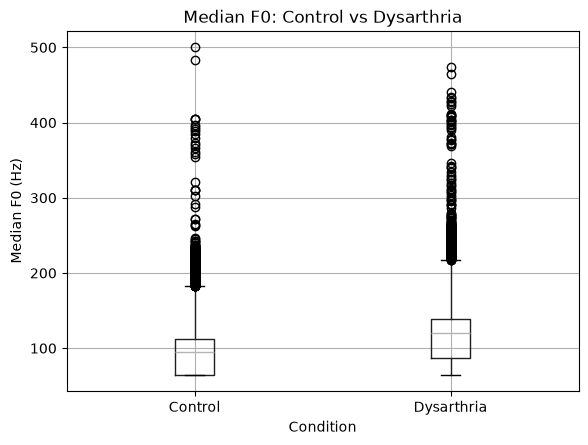

In [17]:
plt.figure(figsize=(8, 5))

pitch_df.boxplot(
    column="median_f0",
    by="condition"
)

plt.title("Median F0: Control vs Dysarthria")
plt.suptitle("")
plt.xlabel("Condition")
plt.ylabel("Median F0 (Hz)")

plt.show()

<Figure size 800x500 with 0 Axes>

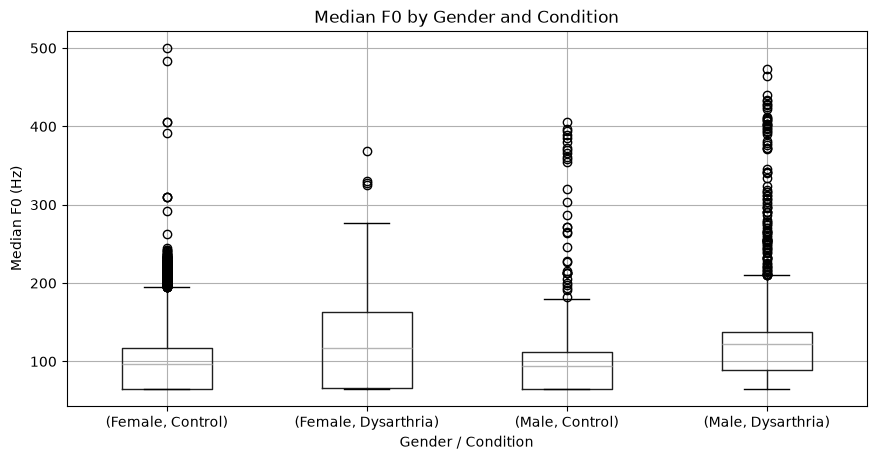

In [18]:
plt.figure(figsize=(8, 5))

pitch_df.boxplot(
    column="median_f0",
    by=["gender", "condition"],
    figsize=(10, 5)
)

plt.title("Median F0 by Gender and Condition")
plt.suptitle("")
plt.xlabel("Gender / Condition")
plt.ylabel("Median F0 (Hz)")

plt.show()

In [19]:
def extract_speech_features(file_path):

    try:
        audio, sr = librosa.load(
            file_path,
            sr=None
        )

        if len(audio) == 0:
            return None

        total_duration = len(audio) / sr

        intervals = librosa.effects.split(
            audio,
            top_db=30
        )

        speech_duration = 0

        for start, end in intervals:
            speech_duration += (end - start) / sr

        silence_duration = total_duration - speech_duration

        number_of_segments = len(intervals)

        if number_of_segments > 0:
            average_segment_duration = (
                speech_duration / number_of_segments
            )
        else:
            average_segment_duration = np.nan

        speech_ratio = speech_duration / total_duration

        return {
            "duration": total_duration,
            "speech_duration": speech_duration,
            "silence_duration": silence_duration,
            "speech_ratio": speech_ratio,
            "number_of_segments": number_of_segments,
            "average_segment_duration": average_segment_duration
        }

    except Exception as e:

        print("ERROR:", file_path, e)

        return None

In [20]:
speech_results = []

for index, row in df.iterrows():

    features = extract_speech_features(row["file"])

    if features is None:
        continue

    features["condition"] = row["condition"]
    features["gender"] = row["gender"]
    features["speaker"] = row["speaker"]
    features["microphone"] = row["microphone"]

    speech_results.append(features)

    if index % 500 == 0:
        print("Processed:", index)

Processed: 0
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
Processed: 5500
Processed: 6000
ERROR: ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0067.wav Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0067.wav': Format not recognised.
ERROR: ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0068.wav Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0068.wav': Format not recognised.
Processed: 6500
Processed: 7000
Processed: 7500
Processed: 8000
Processed: 8500
Processed: 9000
Processed: 9500
Processed: 10000
Processed: 10500
Processed: 11000
Processed: 11500
Processed: 12000
Processed: 12500
Processed: 13000
Processed: 13500
Processed: 14000
Processed: 14500
Processed: 15000
Processed: 15500
Processed: 16000
Processed: 16500
Processed: 17000
Processed: 17500


In [21]:
speech_df = pd.DataFrame(speech_results)

print(speech_df.shape)
print(speech_df.head())

(17632, 10)
   duration  speech_duration  silence_duration  speech_ratio  \
0      9.30            6.612             2.688      0.710968   
1      7.35            5.878             1.472      0.799728   
2      5.25            5.250             0.000      1.000000   
3      4.65            4.650             0.000      1.000000   
4      2.25            2.240             0.010      0.995556   

   number_of_segments  average_segment_duration condition  gender speaker  \
0                   7                  0.944571   Control  Female    FC01   
1                   3                  1.959333   Control  Female    FC01   
2                   1                  5.250000   Control  Female    FC01   
3                   1                  4.650000   Control  Female    FC01   
4                   1                  2.240000   Control  Female    FC01   

  microphone  
0   arrayMic  
1   arrayMic  
2   arrayMic  
3   arrayMic  
4   arrayMic  


In [22]:
speech_summary = speech_df.groupby("condition")[
    [
        "duration",
        "speech_duration",
        "silence_duration",
        "speech_ratio",
        "number_of_segments",
        "average_segment_duration"
    ]
].mean()

print(speech_summary)

            duration  speech_duration  silence_duration  speech_ratio  \
condition                                                               
Control     2.820662         2.113245          0.707417      0.748894   
Dysarthria  3.615179         2.130502          1.484677      0.580010   

            number_of_segments  average_segment_duration  
condition                                                 
Control               1.420602                  1.838770  
Dysarthria            2.167557                  1.287342  


In [23]:
print(df.columns)
print(df.head())

Index(['file', 'group', 'gender', 'condition', 'filename', 'microphone',
       'speaker', 'session', 'recording_number'],
      dtype='str')
                                                file  group  gender condition  \
0  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...  F_Con  Female   Control   
1  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...  F_Con  Female   Control   
2  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...  F_Con  Female   Control   
3  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...  F_Con  Female   Control   
4  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...  F_Con  Female   Control   

                        filename microphone speaker session recording_number  
0  wav_arrayMic_FC01S01_0001.wav   arrayMic    FC01     S01             0001  
1  wav_arrayMic_FC01S01_0002.wav   arrayMic    FC01     S01             0002  
2  wav_arrayMic_FC01S01_0003.wav   arrayMic    FC01     S01             0003  
3  wav_arrayMic_FC01S01_0004.wav   arrayMic    FC01    

In [24]:
# Severity mapping for TORGO dysarthric speakers

severity_map = {
    "F03": "Low",
    "F04": "Low",
    "M03": "Low",

    "F01": "Medium",
    "M05": "Medium",

    "M01": "High",
    "M02": "High",
    "M04": "High"
}

# Add severity column
df["severity"] = df["speaker"].map(severity_map)

# Set Control speakers as Control
df.loc[df["condition"] == "Control", "severity"] = "Control"

# Check the result
print(df[["speaker", "condition", "gender", "severity"]].head(20))

   speaker condition  gender severity
0     FC01   Control  Female  Control
1     FC01   Control  Female  Control
2     FC01   Control  Female  Control
3     FC01   Control  Female  Control
4     FC01   Control  Female  Control
5     FC01   Control  Female  Control
6     FC01   Control  Female  Control
7     FC01   Control  Female  Control
8     FC01   Control  Female  Control
9     FC01   Control  Female  Control
10    FC01   Control  Female  Control
11    FC01   Control  Female  Control
12    FC01   Control  Female  Control
13    FC01   Control  Female  Control
14    FC01   Control  Female  Control
15    FC01   Control  Female  Control
16    FC01   Control  Female  Control
17    FC01   Control  Female  Control
18    FC01   Control  Female  Control
19    FC01   Control  Female  Control


In [25]:
print(df["severity"].value_counts())

severity
Control    11456
Low         2960
High        2300
Medium       919
Name: count, dtype: int64


In [26]:
print(pd.crosstab(df["severity"], df["gender"]))


gender    Female  Male
severity              
Control     4678  6778
High           0  2300
Low         2123   837
Medium       268   651


In [27]:
print(
    df.groupby(["severity", "gender"])["speaker"]
      .unique()
)

severity  gender
Control   Female          [FC01, FC02, FC03]
          Male      [MC01, MC02, MC03, MC04]
High      Male               [M01, M02, M04]
Low       Female                  [F03, F04]
          Male                         [M03]
Medium    Female                       [F01]
          Male                         [M05]
Name: speaker, dtype: object


In [28]:
N = 5

selected_list = []

for severity in df["severity"].dropna().unique():
    for gender in df["gender"].unique():

        subset = df[
            (df["severity"] == severity) &
            (df["gender"] == gender)
        ]

        if len(subset) > 0:
            selected_list.append(
                subset.sample(
                    n=min(N, len(subset)),
                    random_state=42
                )
            )

selected_samples = pd.concat(
    selected_list,
    ignore_index=True
)

print(
    selected_samples[
        ["severity", "gender", "speaker", "filename", "file"]
    ].to_string(index=False)
)

severity gender speaker                      filename                                                              file
 Control Female    FC03 wav_arrayMic_FC03S03_0192.wav ../torgo\F_Con\wav_arrayMic_FC03S03\wav_arrayMic_FC03S03_0192.wav
 Control Female    FC01 wav_arrayMic_FC01S01_0034.wav ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayMic_FC01S01_0034.wav
 Control Female    FC03  wav_headMic_FC03S01_0010.wav   ../torgo\F_Con\wav_headMic_FC03S01\wav_headMic_FC03S01_0010.wav
 Control Female    FC03  wav_headMic_FC03S02_0302.wav   ../torgo\F_Con\wav_headMic_FC03S02\wav_headMic_FC03S02_0302.wav
 Control Female    FC02  wav_headMic_FC02S03_0810.wav   ../torgo\F_Con\wav_headMic_FC02S03\wav_headMic_FC02S03_0810.wav
 Control   Male    MC01 wav_arrayMic_MC01S02_0006.wav ../torgo\M_Con\wav_arrayMic_MC01S02\wav_arrayMic_MC01S02_0006.wav
 Control   Male    MC04 wav_arrayMic_MC04S01_0286.wav ../torgo\M_Con\wav_arrayMic_MC04S01\wav_arrayMic_MC04S01_0286.wav
 Control   Male    MC04  wav_headMic_MC0

In [29]:
print(
    selected_samples
    .groupby(["severity", "gender"])
    .size()
)

severity  gender
Control   Female    5
          Male      5
High      Male      5
Low       Female    5
          Male      5
Medium    Female    5
          Male      5
dtype: int64


In [30]:
print(severity)

High


In [38]:
from pathlib import Path
import pandas as pd

waveform_path = Path.cwd().parent / "torgo_waveform_features.csv"

waveform_df = pd.read_csv(waveform_path)

print(waveform_df.shape)
print(waveform_df.head())

(17632, 10)
   index  duration       rms       zcr  mean_amplitude  max_amplitude  \
0      0      9.30  0.022353  0.333723        0.015805       0.506134   
1      1      7.35  0.025352  0.306692        0.017020       0.506470   
2      2      5.25  0.003137  0.573029        0.002655       0.050323   
3      3      4.65  0.026444  0.135317        0.019084       0.252380   
4      4      2.25  0.007828  0.558243        0.005541       0.248322   

  condition  gender speaker microphone  
0   Control  Female    FC01   arrayMic  
1   Control  Female    FC01   arrayMic  
2   Control  Female    FC01   arrayMic  
3   Control  Female    FC01   arrayMic  
4   Control  Female    FC01   arrayMic  


In [39]:
Path.cwd().parent

WindowsPath('c:/Users/DELL/Downloads/NIT SIKKIM')

In [40]:
print(waveform_df.columns.tolist())

['index', 'duration', 'rms', 'zcr', 'mean_amplitude', 'max_amplitude', 'condition', 'gender', 'speaker', 'microphone']


In [41]:
# Severity mapping for TORGO speakers

severity_map = {
    # Control speakers
    "FC01": "Control",
    "FC02": "Control",
    "FC03": "Control",
    "MC01": "Control",
    "MC02": "Control",
    "MC03": "Control",
    "MC04": "Control",

    # Dysarthria severity
    "F03": "Low",
    "F04": "Low",
    "M03": "Low",

    "F01": "Medium",
    "M05": "Medium",

    "M01": "High",
    "M02": "High",
    "M04": "High"
}

waveform_df["severity"] = waveform_df["speaker"].map(severity_map)

print(waveform_df["severity"].value_counts())

severity
Control    11455
Low         2960
High        2300
Medium       917
Name: count, dtype: int64


In [42]:
print(
    waveform_df.groupby(["severity", "gender"])
    .size()
    .unstack(fill_value=0)
)

gender    Female  Male
severity              
Control     4677  6778
High           0  2300
Low         2123   837
Medium       266   651


In [44]:
features = [
    "duration",
    "rms",
    "zcr",
    "mean_amplitude",
    "max_amplitude"
]

severity_summary = (
    waveform_df.groupby("severity")[features]
    .mean()
    .reindex(["Control", "Low", "Medium", "High"])
)

print(severity_summary.round(4))


          duration     rms     zcr  mean_amplitude  max_amplitude
severity                                                         
Control     2.8207  0.0381  0.2938          0.0282         0.5095
Low         3.1125  0.0358  0.3046          0.0268         0.5077
Medium      4.0466  0.0742  0.1153          0.0626         0.5860
High        4.0901  0.0700  0.1979          0.0559         0.6194


<Figure size 800x500 with 0 Axes>

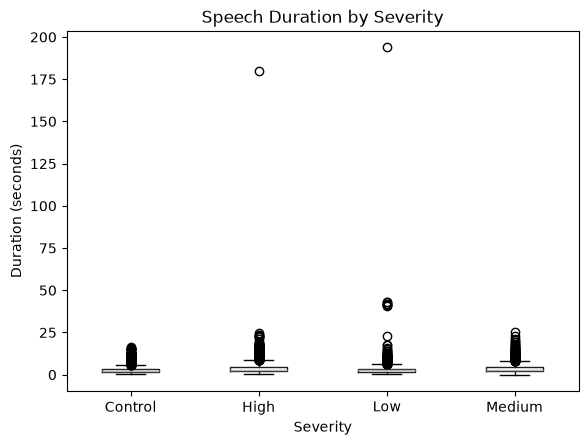

In [45]:
import matplotlib.pyplot as plt

severity_order = ["Control", "Low", "Medium", "High"]

plt.figure(figsize=(8, 5))

waveform_df.boxplot(
    column="duration",
    by="severity",
    grid=False
)

plt.title("Speech Duration by Severity")
plt.suptitle("")
plt.xlabel("Severity")
plt.ylabel("Duration (seconds)")
plt.show()

<Figure size 800x500 with 0 Axes>

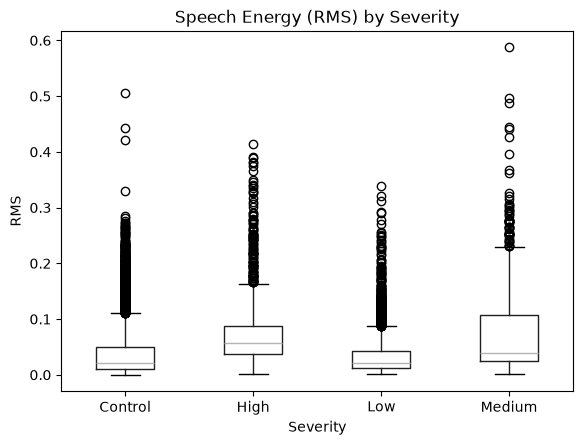

In [47]:
plt.figure(figsize=(8, 5))

waveform_df.boxplot(
    column="rms",
    by="severity",
    grid=False
)

plt.title("Speech Energy (RMS) by Severity")
plt.suptitle("")
plt.xlabel("Severity")
plt.ylabel("RMS")
plt.show()

<Figure size 800x500 with 0 Axes>

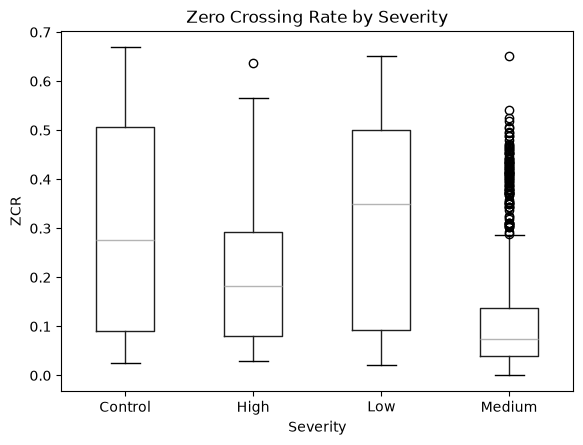

In [48]:
plt.figure(figsize=(8, 5))

waveform_df.boxplot(
    column="zcr",
    by="severity",
    grid=False
)

plt.title("Zero Crossing Rate by Severity")
plt.suptitle("")
plt.xlabel("Severity")
plt.ylabel("ZCR")
plt.show()

In [49]:
gender_summary = (
    waveform_df.groupby(["severity", "gender"])[features]
    .mean()
    .round(4)
)

print(gender_summary)


                 duration     rms     zcr  mean_amplitude  max_amplitude
severity gender                                                         
Control  Female    2.9344  0.0375  0.3085          0.0271         0.5626
         Male      2.7422  0.0386  0.2836          0.0290         0.4729
High     Male      4.0901  0.0700  0.1979          0.0559         0.6194
Low      Female    2.9486  0.0335  0.3106          0.0252         0.4313
         Male      3.5282  0.0417  0.2894          0.0308         0.7016
Medium   Female    2.7988  0.0351  0.2192          0.0273         0.3578
         Male      4.5564  0.0902  0.0728          0.0771         0.6792


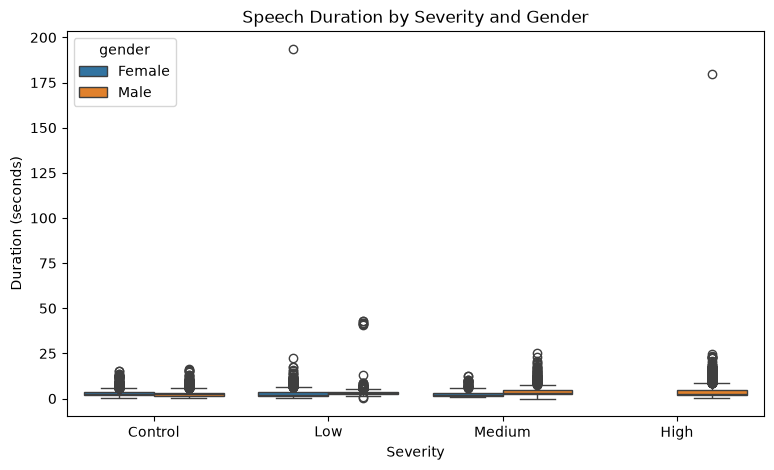

In [51]:
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=waveform_df,
    x="severity",
    y="duration",
    hue="gender",
    order=["Control", "Low", "Medium", "High"]
)

plt.title("Speech Duration by Severity and Gender")
plt.xlabel("Severity")
plt.ylabel("Duration (seconds)")
plt.show()

In [52]:
ml_features = [
    "duration",
    "rms",
    "zcr",
    "mean_amplitude",
    "max_amplitude"
]

ml_df = waveform_df.dropna(
    subset=ml_features + ["severity", "speaker"]
).copy()

X = ml_df[ml_features]
y = ml_df["severity"]
groups = ml_df["speaker"]

print("Samples:", len(ml_df))
print("Features:", ml_features)
print("\nClasses:")
print(y.value_counts())

Samples: 17632
Features: ['duration', 'rms', 'zcr', 'mean_amplitude', 'max_amplitude']

Classes:
severity
Control    11455
Low         2960
High        2300
Medium       917
Name: count, dtype: int64


In [53]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

accuracies = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    acc = accuracy_score(y_test, predictions)
    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    accuracies.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold}")
    print("Accuracy:", round(acc, 4))
    print("Macro F1:", round(f1, 4))
    print()
    
print("Average Accuracy:", round(np.mean(accuracies), 4))
print("Average Macro F1:", round(np.mean(f1_scores), 4))

Fold 1
Accuracy: 0.4769
Macro F1: 0.3292

Fold 2
Accuracy: 0.5171
Macro F1: 0.3624

Fold 3
Accuracy: 0.4627
Macro F1: 0.34

Average Accuracy: 0.4855
Average Macro F1: 0.3439


In [55]:
final_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

final_model.fit(X, y)

importance = pd.DataFrame({
    "feature": ml_features,
    "importance": final_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(importance)

          feature  importance
2             zcr    0.293921
3  mean_amplitude    0.185883
0        duration    0.182862
4   max_amplitude    0.173805
1             rms    0.163529


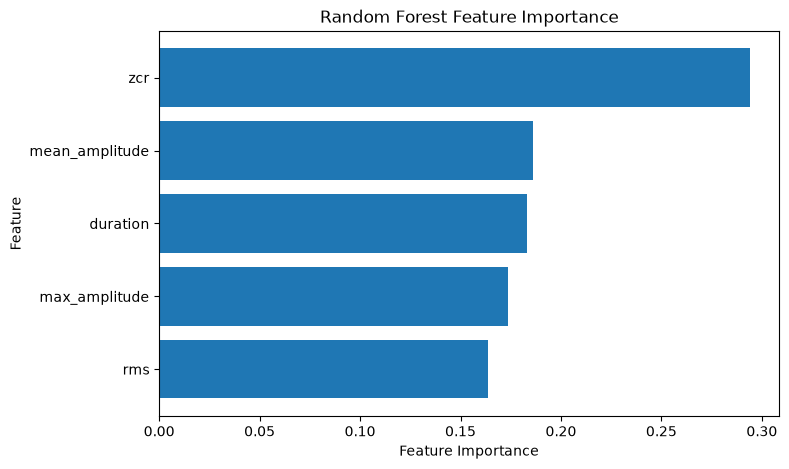

In [56]:
plt.figure(figsize=(8, 5))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [57]:
sample_df = (
    waveform_df
    .dropna(subset=["severity"])
    .groupby(["severity", "gender"], group_keys=False)
    .head(5)
)

print(
    sample_df.groupby(["severity", "gender"])
    .size()
)

severity  gender
Control   Female    5
          Male      5
High      Male      5
Low       Female    5
          Male      5
Medium    Female    5
          Male      5
dtype: int64


In [59]:
print(waveform_df["severity"].value_counts())

severity
Control    11455
Low         2960
High        2300
Medium       917
Name: count, dtype: int64


In [60]:
print(
    waveform_df.groupby(["severity", "gender"])
    .size()
    .unstack(fill_value=0)
)

gender    Female  Male
severity              
Control     4677  6778
High           0  2300
Low         2123   837
Medium       266   651


In [61]:
print(severity_summary.round(4))

          duration     rms     zcr  mean_amplitude  max_amplitude
severity                                                         
Control     2.8207  0.0381  0.2938          0.0282         0.5095
Low         3.1125  0.0358  0.3046          0.0268         0.5077
Medium      4.0466  0.0742  0.1153          0.0626         0.5860
High        4.0901  0.0700  0.1979          0.0559         0.6194


In [62]:
print(gender_summary)

                 duration     rms     zcr  mean_amplitude  max_amplitude
severity gender                                                         
Control  Female    2.9344  0.0375  0.3085          0.0271         0.5626
         Male      2.7422  0.0386  0.2836          0.0290         0.4729
High     Male      4.0901  0.0700  0.1979          0.0559         0.6194
Low      Female    2.9486  0.0335  0.3106          0.0252         0.4313
         Male      3.5282  0.0417  0.2894          0.0308         0.7016
Medium   Female    2.7988  0.0351  0.2192          0.0273         0.3578
         Male      4.5564  0.0902  0.0728          0.0771         0.6792


In [63]:
print(
    waveform_df.groupby("severity")[
        ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
    ].mean().reindex(["Control", "Low", "Medium", "High"]).round(4)
)

          duration     rms     zcr  mean_amplitude  max_amplitude
severity                                                         
Control     2.8207  0.0381  0.2938          0.0282         0.5095
Low         3.1125  0.0358  0.3046          0.0268         0.5077
Medium      4.0466  0.0742  0.1153          0.0626         0.5860
High        4.0901  0.0700  0.1979          0.0559         0.6194


In [64]:
print(importance)

          feature  importance
2             zcr    0.293921
3  mean_amplitude    0.185883
0        duration    0.182862
4   max_amplitude    0.173805
1             rms    0.163529


In [66]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier

In [67]:
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [68]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Features
ml_features = [
    "duration",
    "rms",
    "zcr",
    "mean_amplitude",
    "max_amplitude"
]

ml_df = waveform_df.dropna(
    subset=ml_features + ["severity", "speaker"]
).copy()

X = ml_df[ml_features]
y = ml_df["severity"]
groups = ml_df["speaker"]

# Speaker-independent cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

accuracies = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    accuracies.append(accuracy)
    f1_scores.append(f1)

    print(f"Fold {fold}")
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(f1, 4))
    print()

print("--------------------------------")
print("FINAL RESULTS")
print("--------------------------------")
print("Average Accuracy:", round(np.mean(accuracies), 4))
print("Average Macro F1:", round(np.mean(f1_scores), 4))

Fold 1
Accuracy: 0.4769
Macro F1: 0.3292

Fold 2
Accuracy: 0.5171
Macro F1: 0.3624

Fold 3
Accuracy: 0.4627
Macro F1: 0.34

--------------------------------
FINAL RESULTS
--------------------------------
Average Accuracy: 0.4855
Average Macro F1: 0.3439
